<a href="https://colab.research.google.com/github/Mahmoud4Younis/Handlig-Distribution/blob/main/Handle_Data_Distributions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [140]:
!pip install ucimlrepo

In [141]:
import matplotlib.pyplot as plt
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Fetch dataset
abalone = fetch_ucirepo(id=1)

# Features and target
X = abalone.data.features
y = abalone.data.targets

# Combine into one DataFrame
df = pd.concat([X, y], axis=1)

# Display DataFrame
df.head()

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [142]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   object 
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole_weight    4177 non-null   float64
 5   Shucked_weight  4177 non-null   float64
 6   Viscera_weight  4177 non-null   float64
 7   Shell_weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 293.8+ KB


In [143]:
df.shape

(4177, 9)

In [144]:
df.isna().sum()/df.shape[0]*100

,0
Sex,0.0
Length,0.0
Diameter,0.0
Height,0.0
Whole_weight,0.0
Shucked_weight,0.0
Viscera_weight,0.0
Shell_weight,0.0
Rings,0.0


In [145]:
df.duplicated().sum()

np.int64(0)

In [146]:
df['Sex'].unique()

array(['M', 'F', 'I'], dtype=object)

In [147]:
encode={"M":0,"F":1,"I":2}
df['Sex'].replace(encode,inplace=True)
df['Sex'].unique()

/tmp/ipykernel_432/3881868110.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Sex'].replace(encode,inplace=True)
/tmp/ipykernel_432/3881868110.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Sex'].replace(encode,inplace=True)


array([0, 1, 2])

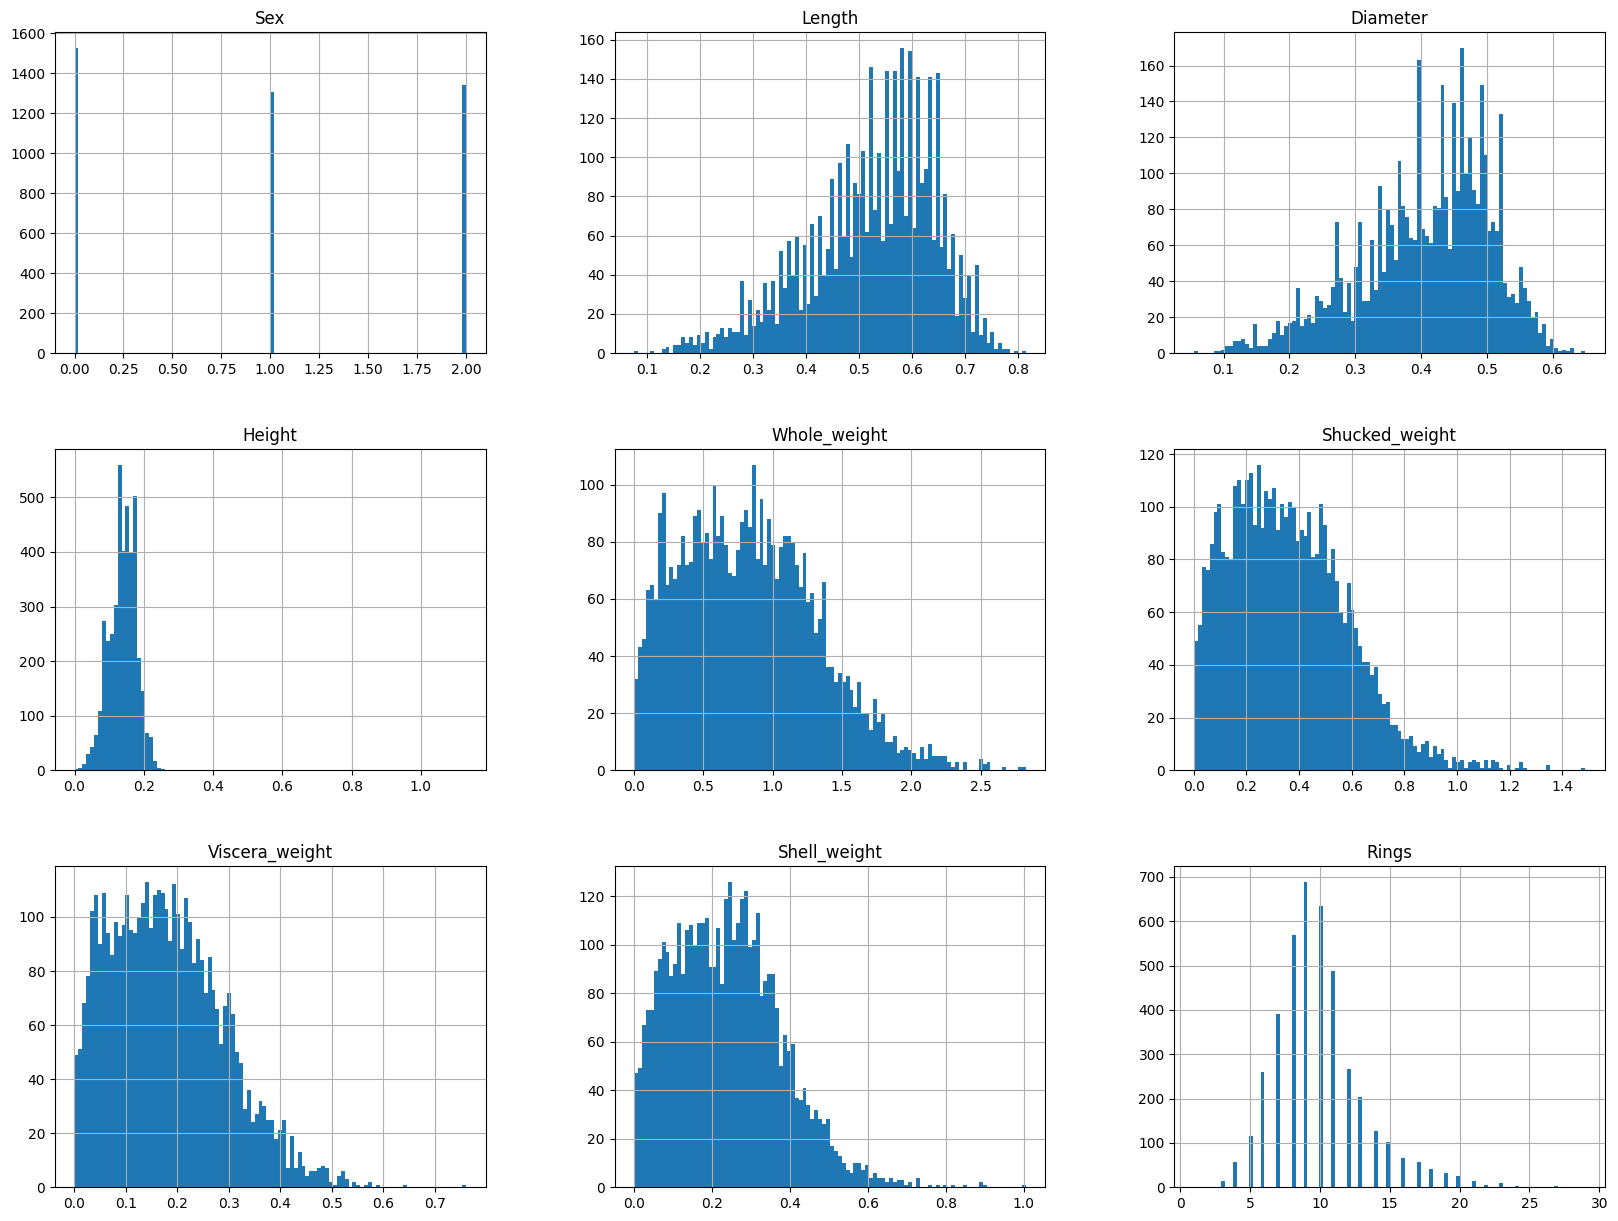

In [148]:
df.hist(figsize=(20,15),bins=100)
plt.show()

In [149]:
import pandas as pd

columns = [
    'Length', 'Diameter', 'Height',
    'Whole_weight', 'Shucked_weight',
    'Viscera_weight', 'Shell_weight', 'Rings'
]

results = []

for col in columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    results.append({
        'Column': col,
        'Skewness': df[col].skew(),
        'Kurtosis': df[col].kurt(),
        'Outliers Count': len(outliers),
        'Outliers Percentage': len(outliers) / len(df) * 100,
        'Lower Limit': lower_limit,
        'Upper Limit': upper_limit
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Column,Skewness,Kurtosis,Outliers Count,Outliers Percentage,Lower Limit,Upper Limit
0,Length,-0.640,0.065,49,1.173,0.203,0.862
1,Diameter,-0.609,-0.045,59,1.412,0.155,0.675
2,Height,3.129,76.026,29,0.694,0.040,0.240
3,Whole_weight,0.531,-0.024,30,0.718,-0.626,2.220
4,Shucked_weight,0.719,0.595,48,1.149,-0.288,0.976
5,Viscera_weight,0.592,0.084,26,0.622,-0.146,0.492
6,Shell_weight,0.621,0.532,35,0.838,-0.168,0.628
7,Rings,1.114,2.331,278,6.655,3.500,15.500



**NOTE :**

We noticed that **Height** has the highest Kurtosis value, along with a strong Positive Skewness, indicating a highly asymmetric distribution with a heavy right tail.

On the other hand, **Rings** has the highest number of Outliers. However, this may be natural, as some abalones may have significantly more rings than others, indicating differences in their ages. Therefore, these values should not be considered errors or removed without further investigation.


In [150]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

In [151]:
x = df.drop("Rings",axis=1)
y = df["Rings"]

In [152]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [153]:
model = LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [154]:
y_pred = model.predict(x_test)
r2_score(y_pred,y_test)

0.17171629357316942

In [155]:
df.describe()

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,0.955470,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,0.827815,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.000000,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,0.000000,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,1.000000,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,2.000000,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,2.000000,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


In [156]:
problem_dists =[
    'Length', 'Diameter', 'Height',
    'Whole_weight', 'Shucked_weight',
    'Viscera_weight', 'Shell_weight', 'Rings']

In [157]:
df[problem_dists] = df[problem_dists].apply(lambda x: np.log(x+1))

In [158]:
import pandas as pd

columns = [
    'Length', 'Diameter', 'Height',
    'Whole_weight', 'Shucked_weight',
    'Viscera_weight', 'Shell_weight', 'Rings'
]

results = []

for col in columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    results.append({
        'Column': col,
        'Skewness': df[col].skew(),
        'Kurtosis': df[col].kurt(),
        'Outliers Count': len(outliers),
        'Outliers Percentage': len(outliers) / len(df) * 100,
        'Lower Limit': lower_limit,
        'Upper Limit': upper_limit
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Column,Skewness,Kurtosis,Outliers Count,Outliers Percentage,Lower Limit,Upper Limit
0,Length,-0.852,0.530,75,1.796,0.210,0.641
1,Diameter,-0.787,0.306,90,2.155,0.162,0.530
2,Height,1.100,23.382,42,1.006,0.043,0.219
3,Whole_weight,-0.038,-0.696,0,0.000,-0.236,1.369
4,Shucked_weight,0.306,-0.349,16,0.383,-0.184,0.761
5,Viscera_weight,0.376,-0.366,9,0.215,-0.115,0.430
6,Shell_weight,0.315,-0.212,16,0.383,-0.121,0.528
7,Rings,-0.061,0.922,210,5.028,1.766,2.916


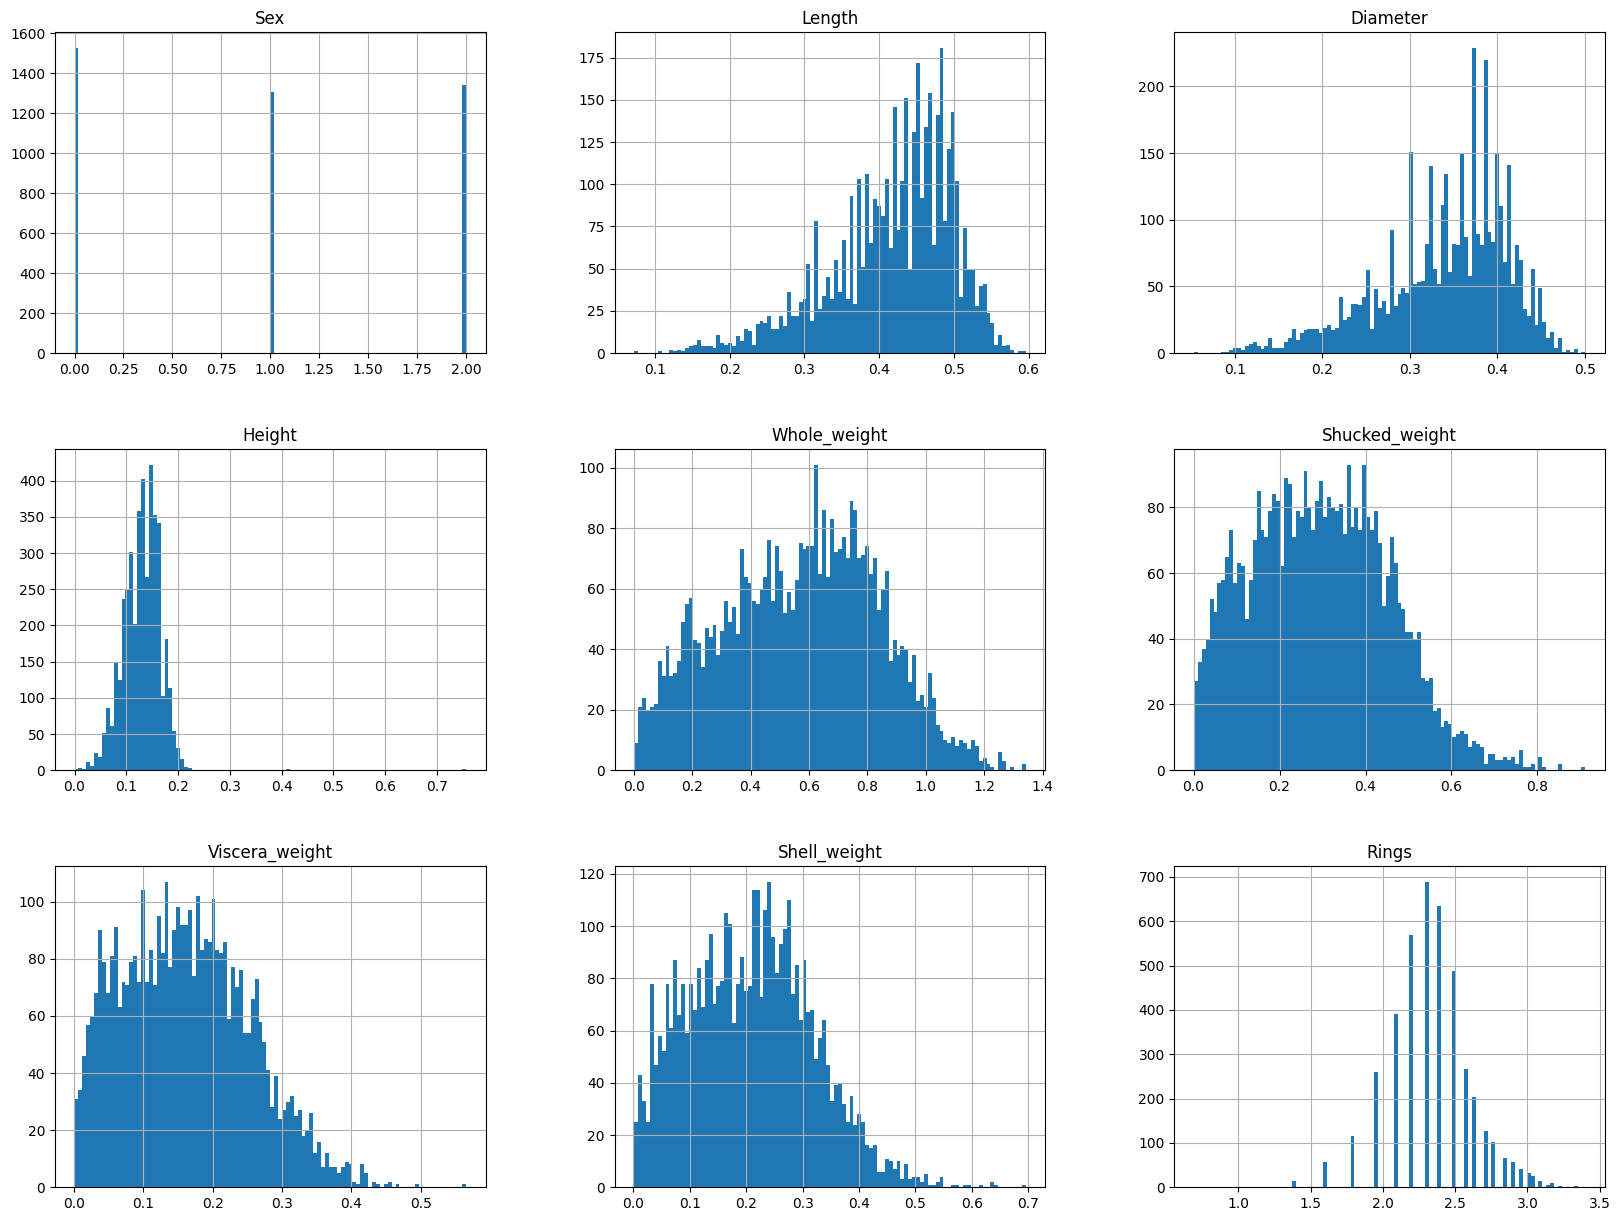

In [159]:
df.hist(figsize=(20,15),bins=100)
plt.show()

In [160]:
x = df.drop("Rings",axis=1)
y = df["Rings"]

In [161]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [162]:
model = LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [163]:
y_pred = model.predict(x_test)
r2_score(y_pred,y_test)

0.4482287901494407


**NOTE :**
After applying the Log Transformation to the selected features, the model achieved a higher R² score, indicating improved predictive performance.


In [164]:
def replace_outliers_with_nan(data, column):
    """
    Replace outliers in the specified column with NaN using the IQR method.
    """
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Replace outliers with NaN
    data[column] = data[column].apply(
        lambda x: np.nan if (x < lower_bound or x > upper_bound) else x
    )
    return data

In [165]:
x = df.drop("Rings",axis=1)
y = df["Rings"]

In [166]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [167]:
model = LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [168]:
y_pred = model.predict(x_test)
r2_score(y_pred,y_test)

0.4482287901494407

**NOTE:**
Even after removing the outliers, the R² score remained unchanged , WHY?
